# Figure 5 - Analysis of the data-driven model (pan-cancer; BRCA/CRC in the supplement)

Figure 5 (`fig5`, pan-cancer):
- a: AUROC against the number of selected TSSs (k) per fragmentomic feature (solid = best configuration at that k, dashed = mean over configurations);
- b: the same per classifier;
- c: AUROC by aggregation level: each feature on the pooled profile of all TSSs (one value per sample), over 39 chromosome arms and over 50 Hallmark gene sets (pooled profile filled, averaged per-TSS values open).

`figS_model_brca_crc` draws the same panels for BRCA/CRC plus a label-permutation panel: pooled out-of-fold ROC of the fully nested procedure with true and with permuted diagnosis labels.

The per-configuration sweep of a, b is descriptive (best configuration picked on the outer test folds); the dash-dotted line is the fully nested AUROC.

Source data: `fig5_auc_sweep.csv`, `fig5c_resolution.csv`, `fig5_status.csv` (`export/export_fig5.py`); `figS5_nested_runs.csv`, `figS5_nested_oof.csv` (`export/export_figS5_nested.py`; a run not yet aggregated is drawn from its finished folds with `--draft` and marked as such).

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch -----------------------------------------------------------------
# "all": full cohort; "no_deep": without the 30 deep-sequenced healthy controls (exporters run with
# COHORT_VARIANT=no_deep). Set FIG_COHORT in the environment; missing files fall back to the full cohort.
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import _figstyle as fs

fs.apply()

# Keys must match the `classifier` values in fig5_auc_sweep.csv exactly.
CLASSIFIER_COLORS = {
    "K-Nearest Neighbors": "#0173B2", "Logistic Regression": "#DE8F05",
    "Multi-Layer Perceptron": "#029E73", "Random Forest": "#CC78BC",
    "Support Vector Machine": "#CA3542", "XGBoost": "#CA9161",
}
FEATURE_NAME_MAP = {"fslr": "FSLR", "fslr_coverage": "FSLRC", "griffin_diff": "GD",
                    "rcov": "RCOV", "mwh": "MWH"}
FEATURE_COLORS = {k: fs.FEATURE[v] for k, v in FEATURE_NAME_MAP.items()}   # shared main-figure colors
CLASSIFIER_NAME_MAP = {"K-Nearest Neighbors": "KNN", "Logistic Regression": "LR",
                       "Multi-Layer Perceptron": "MLP", "Random Forest": "RF",
                       "Support Vector Machine": "SVM", "XGBoost": "XGB"}
DD_COLOR = fs.METHOD["Data-driven"]

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
sweep = pd.read_csv(data_path("fig5_auc_sweep.csv"))
res = pd.read_csv(data_path("fig5c_resolution.csv"))
status = pd.read_csv(data_path("fig5_status.csv"))
perm_runs = pd.read_csv(data_path("figS5_nested_runs.csv"))
perm_oof = pd.read_csv(data_path("figS5_nested_oof.csv"))
if "complete" not in perm_runs:
    perm_runs["complete"] = True
perm_runs["complete"] = perm_runs["complete"].fillna(True).astype(bool)
display(perm_runs.drop(columns="source").round(3))
TASKS = [("brca_crc", "Healthy versus BRCA/CRC"), ("pancan", "Healthy versus all seven cancer types (pan-cancer)")]
summary = (sweep.groupby(["task", "feature", "classifier", "weighting_function", "top_genes"])["auc"]
           .mean().rename("mean_full_auc").reset_index().rename(columns={"top_genes": "n_genes"}))
NESTED = res[res["level"] == "individual TSSs"].set_index("task")["auc_fold_mean"].to_dict()
display(status)
for task, _ in TASKS:
    s = summary[summary["task"] == task]
    print(f"{task}: {s.groupby(['feature','classifier','weighting_function','n_genes']).ngroups} configurations in the sweep; "
          f"fully nested AUROC {NESTED[task]:.3f}" + (f"; best configuration (descriptive) {s['mean_full_auc'].max():.3f}" if len(s) else ""))

,task,run,permutation_seed,n_samples,n_folds,auc_fold_mean,auc_fold_sd,auc_pooled_oof,k_grid,complete,true_selection_in_grid
0,pancan,true_labels,NaN,367,10,0.969,0.015,0.967,10 25 50 100 250 500 1000 1500 2500 5000 10000...,True,NaN
1,pancan,perm1,1.0,367,10,0.506,0.111,0.520,10000 all,True,True
2,brca_crc,true_labels,NaN,244,10,0.966,0.029,0.960,10 25 50 100 250 500 1000 1500 2500 5000 10000...,True,NaN
3,brca_crc,perm1,1.0,244,10,0.467,0.162,0.493,10 25 50 100 250 500 1000 1500 2500 5000 10000...,True,True


,task,source,path,rows,expected,state
0,brca_crc,sweep,nested_cv_results_cris/brca_crc_dd_rev_nodeep,18000,18000,complete
1,brca_crc,genome_griffin_diff,extracted_features/tss_sets/genome_pooled_grif...,244,244,complete
2,brca_crc,genome_rcov,extracted_features/tss_sets/genome_pooled_rcov...,244,244,complete
3,brca_crc,genome_mwh,extracted_features/tss_sets/genome_pooled_mwh.npy,244,244,complete
4,brca_crc,genome_fslr,extracted_features/tss_sets/genome_pooled_fslr...,244,244,complete
5,brca_crc,genome_fslr_coverage,extracted_features/tss_sets/genome_pooled_fslr...,244,244,complete
6,pancan,sweep,nested_cv_results_cris/pancan_dd_rev_nodeep,18000,18000,complete
7,pancan,genome_griffin_diff,extracted_features/tss_sets/genome_pooled_grif...,367,367,complete
8,pancan,genome_rcov,extracted_features/tss_sets/genome_pooled_rcov...,367,367,complete
9,pancan,genome_mwh,extracted_features/tss_sets/genome_pooled_mwh_...,367,367,complete


brca_crc: 1800 configurations in the sweep; fully nested AUROC 0.966; best configuration (descriptive) 0.975
pancan: 1800 configurations in the sweep; fully nested AUROC 0.969; best configuration (descriptive) 0.970


## Panels a and b - AUROC against the number of TSSs

In [3]:
from matplotlib.lines import Line2D

SWEEP_YLIM = (0.5, 1.0)


def _style_axis(ax):
    ax.set_xscale("log")
    ax.set_ylim(*SWEEP_YLIM)
    fs.value_grid(ax)


def panel_sweep(ax, task, group_col, colors, name_map, legend_title, style_legend=True):
    s = summary[summary["task"] == task]
    nested = NESTED[task]
    if not len(s):
        ax.text(0.5, 0.5, "Per-configuration sweep pending", transform=ax.transAxes,
                ha="center", va="center", fontsize=fs.FONT, color=fs.NEUTRAL)
        _style_axis(ax)
        ax.set_xlim(8, 20000)
    else:
        order = [k for k in colors if k in set(s[group_col])]   # fixed legend order, the same in both rows
        for key in order:
            agg = s[s[group_col] == key].groupby("n_genes")["mean_full_auc"].agg(["max", "mean"])
            color = colors.get(key, "#999999")
            ax.plot(agg.index, agg["max"], marker="o", markersize=2.6, linewidth=1.1, color=color, zorder=3,
                    label=name_map.get(key, key))
            ax.plot(agg.index, agg["mean"], linestyle="--", linewidth=0.7, color=color, alpha=0.55, zorder=2)
        _style_axis(ax)
    ax.axhline(nested, color="black", linestyle="-.", linewidth=0.7, alpha=0.8, zorder=1)
    ax.text(0.02, nested - 0.008, f"Fully nested procedure: {nested:.3f}", transform=ax.get_yaxis_transform(),
            ha="left", va="top", fontsize=fs.VALUE, zorder=4)
    ax.set_xlabel("Number of selected TSSs (k)")
    ax.set_ylabel("AUROC (mean over outer folds)")
    if len(s):
        h, l = ax.get_legend_handles_labels()   # the panel title names the grouping: no legend title
        leg = ax.legend(h, l, loc="lower right", ncol=3, columnspacing=1.0, handlelength=1.6)
        if style_legend:   # line styles once, in panel a: upper left, below the fully nested label
            ax.add_artist(leg)
            style = [Line2D([0], [0], color=fs.NEUTRAL, linewidth=1.1, marker="o", markersize=2.6),
                     Line2D([0], [0], color=fs.NEUTRAL, linewidth=0.7, linestyle="--", alpha=0.7)]
            ax.legend(style, ["Best configuration", "Mean of configurations"], loc="upper left",
                      bbox_to_anchor=(0.0, 0.85), handlelength=1.6)

## Panel c - AUROC by aggregation level

In [4]:
LEVELS = [("genome-wide", "All TSSs pooled\n(1 value)"), ("chromosome arms", "Chromosome arms\n(39 sets)"),
          ("Hallmark gene sets", "Hallmark sets\n(50 sets)")]
FEAT_ORDER = ["griffin_diff", "fslr", "fslr_coverage", "rcov", "mwh"]


def panel_resolution(ax, task, feature_ncol=5, legends_bottom=False):
    r = res[res["task"] == task]
    offs = dict(zip(FEAT_ORDER, np.linspace(-0.3, 0.3, len(FEAT_ORDER))))
    for xi, (level, _) in enumerate(LEVELS):
        for f in FEAT_ORDER:
            for mode, dx, face in [("pooled", -0.03, None), ("averaged", 0.03, "white")]:
                g = r[(r["level"] == level) & (r["feature"] == f) & (r["mode"] == mode)]
                if not len(g):
                    continue
                c = FEATURE_COLORS[f]
                x = xi + offs[f] + dx
                ax.errorbar(x, g["auc_fold_mean"].iloc[0], yerr=g["auc_fold_sd"].iloc[0], fmt="o", markersize=3.6,
                            color=c, markerfacecolor=face or c, markeredgecolor=c, markeredgewidth=0.9,
                            elinewidth=0.8, capsize=0, alpha=0.95, zorder=3)
        if level == "genome-wide" and len(r[r["level"] == level]) < len(FEAT_ORDER):
            ax.text(xi, 0.4, f"{len(r[r['level'] == level])}/5 features\n(rest pending)", ha="center",
                    fontsize=fs.VALUE, color=fs.NEUTRAL)
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8)
    # reference: the fully nested data-driven model on individual TSSs, as in panels a and b
    ax.axhline(NESTED[task], color="black", linestyle="-.", linewidth=0.7, alpha=0.8, zorder=1)
    ax.text(len(LEVELS) - 0.55, NESTED[task] - 0.008, f"Data-driven model, individual TSSs: {NESTED[task]:.3f}",
            ha="right", va="top", fontsize=fs.VALUE, zorder=4)
    for xi in range(len(LEVELS) - 1):
        ax.axvline(xi + 0.5, color=fs.GRID, linewidth=0.6, zorder=0)
    ax.set_xticks(range(len(LEVELS)))
    ax.set_xticklabels([lab for _, lab in LEVELS])
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.5, len(LEVELS) - 0.5)
    ax.set_ylim(0.3, 1.0)
    ax.set_ylabel("AUROC (mean ± SD over outer folds)")
    fs.value_grid(ax)
    h = [Line2D([], [], marker="o", ls="none", color=FEATURE_COLORS[f], markersize=3.6, label=FEATURE_NAME_MAP[f])
         for f in FEAT_ORDER]
    if legends_bottom:   # one-row Figure 5: both legends in the empty band below AUROC 0.5
        leg = ax.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=5, columnspacing=0.6,
                        handletextpad=0.05, borderaxespad=0.3)
    else:
        leg = ax.legend(handles=h, loc="upper left", bbox_to_anchor=(0.0, 0.94), ncol=feature_ncol, columnspacing=0.8, handletextpad=0.1)
    leg._legend_box.align = "left"
    ax.add_artist(leg)
    h = [Line2D([], [], marker="o", ls="none", color=fs.NEUTRAL, markersize=3.6, label="Pooled profile"),
         Line2D([], [], marker="o", ls="none", color=fs.NEUTRAL, markerfacecolor="white", markeredgewidth=0.9,
                markersize=3.6, label="Averaged per-TSS values")]
    if legends_bottom:
        ax.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.075), ncol=2, columnspacing=1.0,
                  handletextpad=0.05, borderaxespad=0.3)
    else:
        ax.legend(handles=h, loc="upper right", bbox_to_anchor=(1.0, 0.91), ncol=1, handletextpad=0.1)


from sklearn.metrics import roc_curve

C_TRUE, C_PERM = DD_COLOR, fs.NEUTRAL


def panel_permutation(ax, task):
    """Pooled out-of-fold ROC of the fully nested procedure: true labels vs permuted labels."""
    r = perm_runs[perm_runs["task"] == task].set_index("run")
    perms = [p for p in r.index if p != "true_labels"]
    for run in perms:
        d = perm_oof[(perm_oof["task"] == task) & (perm_oof["run"] == run)]
        fpr, tpr, _ = roc_curve(d["y_true"], d["score"])
        note = "" if r.loc[run, "complete"] else f", {int(r.loc[run, 'n_folds'])}/10 folds"
        ax.plot(fpr, tpr, color=C_PERM, lw=0.9, alpha=0.9, zorder=2,
                label=f"Permuted labels: {r.loc[run, 'auc_fold_mean']:.2f}{note}" if run == perms[0] else None)
    d = perm_oof[(perm_oof["task"] == task) & (perm_oof["run"] == "true_labels")]
    fpr, tpr, _ = roc_curve(d["y_true"], d["score"])
    ax.plot(fpr, tpr, color=C_TRUE, lw=1.3, zorder=3, label=f"True labels: {r.loc['true_labels', 'auc_fold_mean']:.3f}")
    ax.plot([0, 1], [0, 1], color=fs.CHANCE, ls=":", lw=0.8, zorder=1)
    if not perms:   # never drawn from data that do not exist
        ax.plot([], [], color=C_PERM, lw=0.9, ls="none", label="Permuted labels: pending")
        ax.text(0.97, 0.42, "Permuted labels:\npending", transform=ax.transAxes, ha="right", va="bottom",
                fontsize=fs.FONT, color=fs.NEUTRAL)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.set_aspect("equal")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    h, l = ax.get_legend_handles_labels()
    order = sorted(range(len(l)), key=lambda i: not l[i].startswith("True"))
    leg = ax.legend([h[i] for i in order], [l[i] for i in order], loc="lower right", handlelength=1.2,
                    title="AUROC (mean over folds)", borderaxespad=0.1)
    leg._legend_box.align = "left"
    return not all(r.loc[p, "complete"] for p in perms)

## Assemble the figures

saved output\no_deep\fig5.png/.pdf at 178 x 70 mm


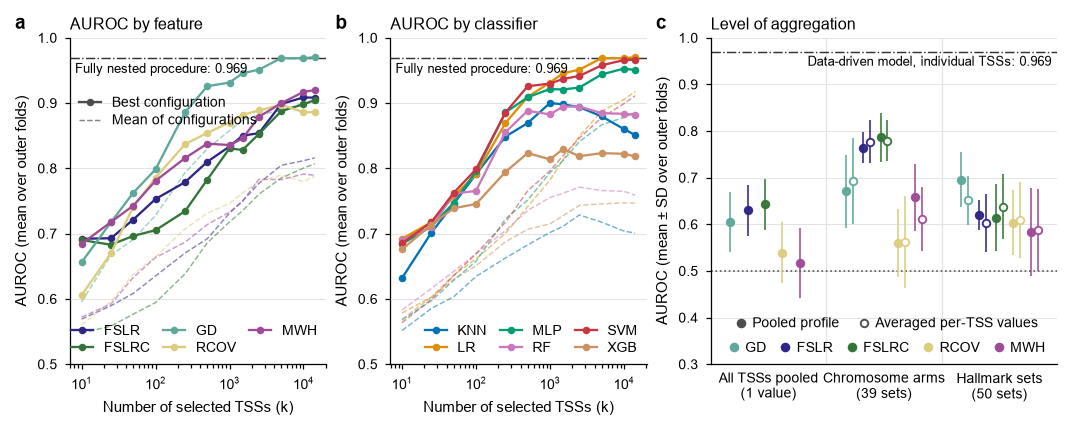

saved output\no_deep\figS_model_brca_crc.png/.pdf at 178 x 114 mm


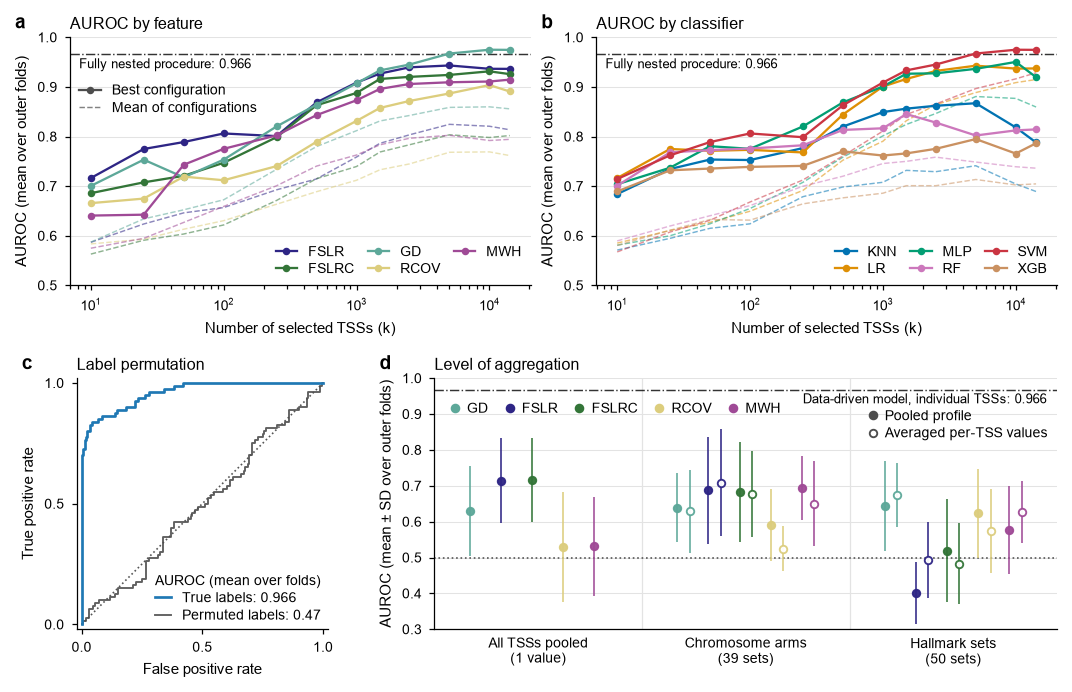

In [5]:
def draw_task(task, stem):
    """Panels a-d at print size (180 mm): a, b on top (shared AUROC axis); c (square ROC) and d below."""
    fig = plt.figure(figsize=fs.size(rows=2, height=4.5), layout="constrained")
    top, bottom = fig.subfigures(2, 1, hspace=0.02)
    a, b = top.subplots(1, 2, sharey=True)
    c, d = bottom.subplots(1, 2, width_ratios=[1, 1.9])
    panel_sweep(a, task, "feature", FEATURE_COLORS, FEATURE_NAME_MAP, "Feature")
    panel_sweep(b, task, "classifier", CLASSIFIER_COLORS, CLASSIFIER_NAME_MAP, "Classifier", style_legend=False)
    b.tick_params(labelleft=True)
    draft = panel_permutation(c, task)   # c: label permutation
    panel_resolution(d, task)            # d: aggregation level
    for ax, letter, title in [(a, "a", "AUROC by feature"), (b, "b", "AUROC by classifier"),
                              (c, "c", "Label permutation"), (d, "d", "Level of aggregation")]:
        fs.panel(ax, letter, title)
    if draft:   # permutation run not aggregated yet (exporter --draft): never overwrite the final figure
        stem += "_draft"
        c.text(0.03, 0.97, "DRAFT: permutation incomplete", transform=c.transAxes, fontsize=fs.VALUE,
               color="#C0392B", va="top")
    fs.save(fig, out_path(stem))
    plt.show()


def draw_main(task, stem):
    """Figure 5: one row, a per feature, b per classifier, c level of aggregation."""
    fig = plt.figure(figsize=fs.size(height=2.75), layout="constrained")
    a, b, c = fig.subplots(1, 3, width_ratios=[1, 1, 1.35])
    panel_sweep(a, task, "feature", FEATURE_COLORS, FEATURE_NAME_MAP, "Feature")
    panel_sweep(b, task, "classifier", CLASSIFIER_COLORS, CLASSIFIER_NAME_MAP, "Classifier", style_legend=False)
    b.sharey(a)
    panel_resolution(c, task, legends_bottom=True)
    for ax, letter, title in [(a, "a", "AUROC by feature"), (b, "b", "AUROC by classifier"),
                              (c, "c", "Level of aggregation")]:
        fs.panel(ax, letter, title)
    fs.save(fig, out_path(stem))
    plt.show()
    return fig


FIG5 = draw_main("pancan", "fig5")             # main figure (Figure 5, fig:dd_analysis)
draw_task("brca_crc", "figS_model_brca_crc")  # the same panels for BRCA/CRC (standalone; the manuscript uses figS_model_analysis)

## Summary numbers

In [6]:
tab = res.assign(cell=res["auc_fold_mean"].map("{:.3f}".format) + " ± " + res["auc_fold_sd"].map("{:.3f}".format))
tab["col"] = tab["level"] + " / " + tab["mode"].fillna("")
display(tab.pivot_table(index=["task", "feature"], columns="col", values="cell", aggfunc="first"))
for task, _ in TASKS:
    s = summary[summary["task"] == task]
    if len(s):
        allk = s[s["n_genes"] == s["n_genes"].max()].groupby("feature")["mean_full_auc"].max()
        print(task, "best configuration at all TSSs, per feature:", allk.round(3).to_dict())

col                        Hallmark gene sets / averaged  \
task     feature                                           
brca_crc fslr                              0.493 ± 0.106   
         fslr_coverage                     0.483 ± 0.113   
         griffin_diff                      0.674 ± 0.088   
         mwh                               0.627 ± 0.087   
         rcov                              0.574 ± 0.117   
         selected per fold                           NaN   
pancan   fslr                              0.603 ± 0.062   
         fslr_coverage                     0.637 ± 0.070   
         griffin_diff                      0.652 ± 0.053   
         mwh                               0.587 ± 0.088   
         rcov                              0.608 ± 0.081   
         selected per fold                           NaN   

col                        Hallmark gene sets / pooled  \
task     feature                                         
brca_crc fslr                            0.400 ± 0.086   
         fslr_coverage                   0.519 ± 0.144   
         griffin_diff                    0.644 ± 0.126   
         mwh                             0.577 ± 0.124   
         rcov                            0.623 ± 0.124   
         selected per fold                         NaN   
pancan   fslr                            0.620 ± 0.032   
         fslr_coverage                   0.614 ± 0.072   
         griffin_diff                    0.696 ± 0.059   
         mwh                             0.584 ± 0.094   
         rcov                            0.603 ± 0.070   
         selected per fold                         NaN   

col                        chromosome arms / averaged  \
task     feature                                        
brca_crc fslr                           0.709 ± 0.149   
         fslr_coverage                  0.676 ± 0.120   
         griffin_diff                   0.629 ± 0.116   
         mwh                            0.650 ± 0.119   
         rcov                           0.524 ± 0.063   
         selected per fold                        NaN   
pancan   fslr                           0.777 ± 0.046   
         fslr_coverage                  0.780 ± 0.044   
         griffin_diff                   0.693 ± 0.092   
         mwh                            0.611 ± 0.069   
         rcov                           0.562 ± 0.098   
         selected per fold                        NaN   

col                        chromosome arms / pooled genome-wide / pooled  \
task     feature                                                           
brca_crc fslr                         0.687 ± 0.148        0.714 ± 0.119   
         fslr_coverage                0.682 ± 0.139        0.716 ± 0.117   
         griffin_diff                 0.639 ± 0.097        0.630 ± 0.125   
         mwh                          0.694 ± 0.089        0.532 ± 0.138   
         rcov                         0.590 ± 0.101        0.530 ± 0.154   
         selected per fold                      NaN                  NaN   
pancan   fslr                         0.764 ± 0.033        0.630 ± 0.054   
         fslr_coverage                0.786 ± 0.053        0.643 ± 0.054   
         griffin_diff                 0.670 ± 0.077        0.604 ± 0.064   
         mwh                          0.658 ± 0.071        0.518 ± 0.075   
         rcov                         0.559 ± 0.073        0.539 ± 0.065   
         selected per fold                      NaN                  NaN   

col                        individual TSSs /   
task     feature                               
brca_crc fslr                             NaN  
         fslr_coverage                    NaN  
         griffin_diff                     NaN  
         mwh                              NaN  
         rcov                             NaN  
         selected per fold      0.966 ± 0.029  
pancan   fslr                             NaN  
         fslr_coverage                    NaN  
  

brca_crc best configuration at all TSSs, per feature: {'fslr': 0.936, 'fslr_coverage': 0.926, 'griffin_diff': 0.975, 'mwh': 0.915, 'rcov': 0.891}
pancan best configuration at all TSSs, per feature: {'fslr': 0.908, 'fslr_coverage': 0.905, 'griffin_diff': 0.97, 'mwh': 0.92, 'rcov': 0.886}
